# Method 1 — Text Mining: skill demand from job postings (Review 2)

**Goal:** turn 7,240 real job descriptions into evidence of *which skills employers ask for*, how those
skills group together, and what topics the postings talk about — and show that the numbers can be trusted.

**Two halves of Method 1.** (a) *Meaning extraction by clustering* is in
`notebooks/text_mining_research.ipynb` (TF-IDF → SVD → K-Means, by Member A). (b) *Skill extraction,
term-document matrix, co-occurrence and topic modelling* are in this notebook. Section 7 joins the two.

**Reads (never edits):** `data/processed/career_market_preprocessed.csv`, `config/review2_skills.json`,
`outputs/text_mining_research/final_cluster_assignments.csv`.

**Writes:** `data/review2/skill_demand.csv` (contract file: `skill, frequency, pct_postings, rank`, exactly
the 20 config skills, ranks 1–20), figures `reports/text_mining/01…05_*.png`, and tables in the same folder.

**Syllabus links (Unit 3 – Text Mining):** pre-processing the text (already done upstream), the
*term-document matrix / bag-of-words* (§2), *meaning extraction beyond bag-of-words* (LDA topics, §5) and
a case study on real data.

**Known limit, stated up front:** the source API returns descriptions truncated at **500 characters**, so
every skill count below is a **lower bound** of how many postings truly require the skill.

In [1]:
import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RS = 42  # every seeded step uses this

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "text_mining"
FIG.mkdir(parents=True, exist_ok=True)

cfg = json.load(open(ROOT / "config" / "review2_skills.json"))
skills = cfg["skills"]
df = pd.read_csv(ROOT / "data" / "processed" / "career_market_preprocessed.csv")
print(f"{len(df):,} postings, {df['role'].nunique()} roles, {len(skills)} skills in the frozen list")

7,240 postings, 10 roles, 20 skills in the frozen list


## 0. Look at the data first

Before extracting anything: size, balance, missing values, duplicates and description length. These
facts explain the limitations that follow.

In [2]:
dup_mask = df["description_raw"].duplicated(keep="first")
uniq = ~dup_mask.values            # first occurrence of every distinct description

profile = pd.Series({
    "postings": len(df),
    "roles": df["role"].nunique(),
    "missing description_raw": int(df["description_raw"].isna().sum()),
    "missing description_clean": int(df["description_clean"].isna().sum()),
    "repeated descriptions (extra copies)": int(dup_mask.sum()),
    "distinct descriptions": int(uniq.sum()),
    "share of descriptions at the 500-char cap (%)": round(100 * (df["description_length"] >= 500).mean(), 1),
    "median description length (chars)": float(df["description_length"].median()),
}, name="value").to_frame()
display(profile)
display(df["role"].value_counts().rename("postings").to_frame())

,value
postings,7240.0
roles,10.0
missing description_raw,0.0
missing description_clean,3.0
repeated descriptions (extra copies),878.0
distinct descriptions,6362.0
share of descriptions at the 500-char cap (%),98.5
median description length (chars),500.0


,postings
role,
Software Engineer,1421
Devops / Cloud Engineer,983
Business Analyst,897
Product Manager,696
Data Scientist,660
Digital Marketing,583
Data Engineer,562
Data Analyst,531
Graphic Designer,461


## 1. Skill extraction (dictionary + regular expressions)

Each skill is detected with a word-boundary regular expression on the lower-cased **raw** description. A
posting counts once per skill however often the skill is mentioned.

**Two versions of the dictionary are kept so the improvement can be measured.**
- **V1** — the original patterns (copied from `scripts/review2_seed.py`, which is **not** run here).
- **V2** — V1 plus fixes found by reading the matches (§8): aliases of the same technology
  (`pyspark`, `ML`, `reactjs`, "search engine optimisation") and removal of ordinary-English uses of
  *spark* ("this spark became…", "spark curiosity") and *excel* ("to excel", "excel at"). **V2 drives every
  result below.** It was frozen before it was tested on postings it had not been designed from (§8).

*Why raw and not `description_clean`?* The clean text is lemmatised, which changes some tokens. The table
below counts both ways, so the choice is evidence-based.

In [3]:
PATTERNS_V1 = {
    "Python": r"\bpython\b", "SQL": r"\bsql\b", "Power BI": r"\bpower\s*bi\b", "Tableau": r"\btableau\b",
    "Excel": r"\bexcel\b", "AWS": r"\baws\b|\bamazon web services\b", "Azure": r"\bazure\b",
    "Google Cloud": r"\bgcp\b|\bgoogle cloud\b", "Docker": r"\bdocker\b",
    "Kubernetes": r"\bkubernetes\b|\bk8s\b", "Machine Learning": r"\bmachine learning\b",
    "Deep Learning": r"\bdeep learning\b", "Java": r"\bjava\b", "JavaScript": r"\bjavascript\b",
    "React": r"\breact\b", "Linux": r"\blinux\b", "SAP": r"\bsap\b", "Spark": r"\bspark\b",
    "Git": r"\bgit\b", "SEO": r"\bseo\b",
}
PATTERNS = dict(PATTERNS_V1)   # V2
PATTERNS["Spark"] = (r"\bpyspark\b|\bapache spark\b|"
                     r"(?<!\bto )(?<!\bthis )\bspark\b(?! (?:your|their|our|my|the|a|an|new|more|curiosity|"
                     r"conversations?|became|joy|interest|innovation|ideas?|passion|change|growth)\b)")
PATTERNS["Machine Learning"] = r"\bmachine learning\b|\bml\b"
PATTERNS["React"] = r"\breact\b|\breactjs\b"
PATTERNS["SEO"] = r"\bseo\b|\bsearch engine optimi[sz]ation\b"
# 'excel' as a verb ("to excel", "you excel", "excel at/in/as/on") is not the spreadsheet.
PATTERNS["Excel"] = (r"(?<!\bto )(?<!\byou )(?<!\bwe )(?<!\bthey )(?<!\bwho )\bexcel\b"
                     r"(?! (?:at|in|as|on)\b)")
assert set(PATTERNS) == set(skills) == set(PATTERNS_V1), "pattern lists must match config/review2_skills.json"

raw = df["description_raw"].fillna("").str.lower()
clean = df["description_clean"].fillna("")
M_v1 = pd.DataFrame({s: raw.str.contains(PATTERNS_V1[s], regex=True) for s in skills})
M = pd.DataFrame({s: raw.str.contains(PATTERNS[s], regex=True) for s in skills})     # V2

# Same patterns on the lemmatised text; the two '-ing' skills need a stem-tolerant pattern there.
clean_patterns = {**PATTERNS, "Machine Learning": r"\bmachine learn|\bml\b", "Deep Learning": r"\bdeep learn"}
M_clean = pd.DataFrame({s: clean.str.contains(clean_patterns[s], regex=True) for s in skills})

compare = pd.DataFrame({"V1_raw": M_v1.sum(), "V2_raw": M.sum(), "V2_on_clean_text": M_clean.sum()})
compare["V2_minus_V1"] = compare["V2_raw"] - compare["V1_raw"]
display(compare.sort_values("V2_raw", ascending=False))
print(f"postings with >= 1 skill   V1: {int((M_v1.sum(axis=1) > 0).sum())}   V2: {int((M.sum(axis=1) > 0).sum())}")
r1 = M_v1.sum().sort_values(ascending=False, kind="stable").index.tolist()
r2 = M.sum().sort_values(ascending=False, kind="stable").index.tolist()
print("top 6 under V1:", r1[:6]); print("top 6 under V2:", r2[:6])

,V1_raw,V2_raw,V2_on_clean_text,V2_minus_V1
Machine Learning,282,381,383,99
AWS,335,335,135,0
Python,296,296,296,0
SQL,290,290,290,0
Azure,254,254,254,0
SEO,185,188,188,3
Kubernetes,145,145,7,0
Google Cloud,131,131,131,0
Spark,76,124,139,48
SAP,114,114,114,0


postings with >= 1 skill   V1: 1625   V2: 1678
top 6 under V1: ['AWS', 'Python', 'SQL', 'Machine Learning', 'Azure', 'SEO']
top 6 under V2: ['Machine Learning', 'AWS', 'Python', 'SQL', 'Azure', 'SEO']


## 2. Term-document matrix and bag-of-words

The **term-document matrix** has one row per posting and one column per term; each cell is a count
(*bag-of-words*: word order is ignored). **TF-IDF** re-weights the counts so words that appear in almost
every posting count less. We build both on `description_clean`, then list the terms that are most
*distinctive* for each role (mean TF-IDF in the role minus the mean over all postings).

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = df["description_clean"].fillna("")
cv = CountVectorizer(min_df=5)
X = cv.fit_transform(texts)
terms = np.array(cv.get_feature_names_out())
sparsity = 100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))
print(f"term-document matrix: {X.shape[0]:,} postings x {X.shape[1]:,} terms, {sparsity:.1f}% of cells are zero")

doc_freq = np.asarray((X > 0).sum(axis=0)).ravel()
top_terms = pd.DataFrame({"term": terms, "postings_containing": doc_freq}).nlargest(15, "postings_containing")
display(top_terms.reset_index(drop=True))

tv = TfidfVectorizer(min_df=5)
T = tv.fit_transform(texts)
tterms = np.array(tv.get_feature_names_out())
overall = np.asarray(T.mean(axis=0)).ravel()
rows = []
for role, idx in df.groupby("role").indices.items():
    lift = np.asarray(T[idx].mean(axis=0)).ravel() - overall
    for rank, j in enumerate(np.argsort(lift)[::-1][:8], 1):
        rows.append({"role": role, "rank": rank, "term": tterms[j], "tfidf_above_average": round(float(lift[j]), 4)})
tfidf_tbl = pd.DataFrame(rows)
tfidf_tbl.to_csv(FIG / "tfidf_distinctive_terms_by_role.csv", index=False)
display(tfidf_tbl.groupby("role")["term"].apply(lambda s: ", ".join(s)).to_frame("most distinctive terms"))

term-document matrix: 7,240 postings x 3,869 terms, 99.0% of cells are zero


,term,postings_containing
0,team,2846
1,role,2760
2,work,2449
3,business,2432
4,experience,2239
5,job,2082
6,datum,1963
7,build,1889
8,design,1851
9,platform,1850


,most distinctive terms
role,
Business Analyst,"business, analyst, requirement, process, funct..."
Data Analyst,"datum, analyst, analytic, data, insight, repor..."
Data Engineer,"data, datum, pipeline, etl, engineer, analytic..."
Data Scientist,"scientist, machine, model, learning, ai, ml, s..."
Devops / Cloud Engineer,"cloud, infrastructure, devop, reliability, pla..."
Digital Marketing,"marketing, digital, campaign, seo, performance..."
Graphic Designer,"graphic, creative, designer, visual, design, b..."
Product Manager,"product, owner, manager, roadmap, customer, vi..."
Project Manager,"project, manager, delivery, end, execution, te..."


## 3. Skill demand: overall and by role

`frequency` = number of postings mentioning the skill; `pct_postings` = share of all 7,240 postings.
Because of the 500-character cut-off these are **lower bounds**, so read the *ranking* more than the
absolute percentages. We also check three things an examiner would ask: coverage (how many postings
mention any listed skill), whether repeated descriptions change the ranking, and how demand differs by role.

In [5]:
N = len(df)
freq = M.sum().rename("frequency").rename_axis("skill").reset_index()
freq["pct_postings"] = (100 * freq["frequency"] / N).round(2)
# Ties are broken alphabetically so the rank is reproducible.
demand = freq.sort_values(["frequency", "skill"], ascending=[False, True]).reset_index(drop=True)
demand["rank"] = np.arange(1, len(demand) + 1)
display(demand)

n_skills = M.sum(axis=1)
coverage = pd.Series({
    "postings mentioning no listed skill": int((n_skills == 0).sum()),
    "postings mentioning >= 1 skill": int((n_skills >= 1).sum()),
    "postings mentioning >= 2 skills": int((n_skills >= 2).sum()),
    "postings mentioning >= 3 skills": int((n_skills >= 3).sum()),
}, name="postings").to_frame()
coverage["% of all postings"] = (100 * coverage["postings"] / N).round(1)
display(coverage)

,skill,frequency,pct_postings,rank
0,Machine Learning,381,5.26,1
1,AWS,335,4.63,2
2,Python,296,4.09,3
3,SQL,290,4.01,4
4,Azure,254,3.51,5
5,SEO,188,2.60,6
6,Kubernetes,145,2.00,7
7,Google Cloud,131,1.81,8
8,Spark,124,1.71,9
9,SAP,114,1.57,10


,postings,% of all postings
postings mentioning no listed skill,5562,76.8
postings mentioning >= 1 skill,1678,23.2
postings mentioning >= 2 skills,621,8.6
postings mentioning >= 3 skills,271,3.7


Spearman correlation between the two rankings: 1.000 (p = 1.4e-29)


,frequency,rank,frequency_distinct_only,rank_distinct_only
skill,,,,
Machine Learning,381,1,358,1
AWS,335,2,315,2
Python,296,3,288,3
SQL,290,4,282,4
Azure,254,5,247,5
SEO,188,6,182,6
Kubernetes,145,7,141,7
Google Cloud,131,8,130,8
Spark,124,9,123,9


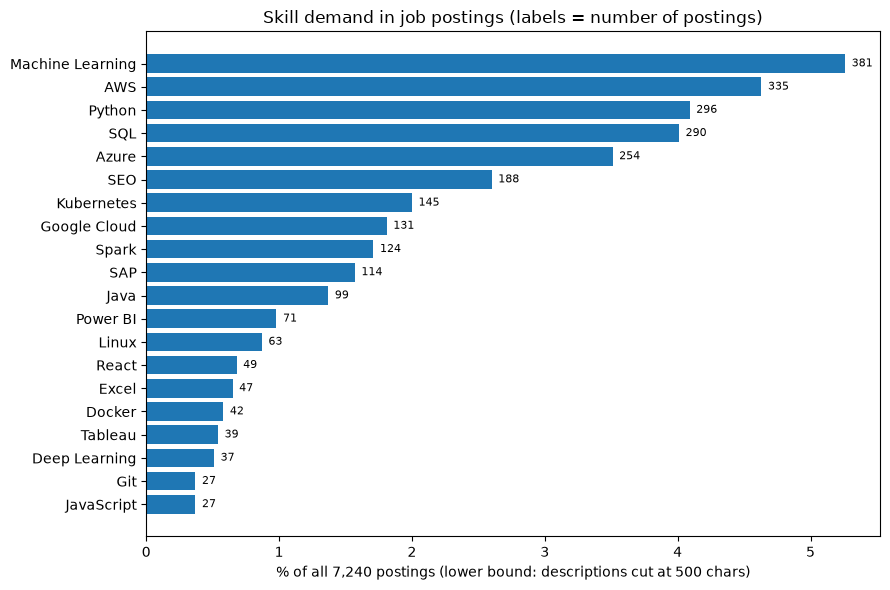

In [6]:
from scipy.stats import spearmanr

# Do the 878 repeated descriptions distort the ranking? Recount on distinct descriptions only.
freq_u = M[uniq].sum().rename("frequency_distinct_only")
chk = demand.set_index("skill").join(freq_u)
chk["pct_distinct_only"] = (100 * chk["frequency_distinct_only"] / int(uniq.sum())).round(2)
chk["rank_distinct_only"] = chk["frequency_distinct_only"].rank(ascending=False, method="min").astype(int)
rho, p = spearmanr(chk["rank"], chk["rank_distinct_only"])
print(f"Spearman correlation between the two rankings: {rho:.3f} (p = {p:.1e})")
display(chk[["frequency", "rank", "frequency_distinct_only", "rank_distinct_only"]])

order = demand["skill"].tolist()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(order[::-1], demand["pct_postings"].values[::-1], color="tab:blue")
for y, (v, f) in enumerate(zip(demand["pct_postings"].values[::-1], demand["frequency"].values[::-1])):
    ax.text(v + 0.05, y, f"{f}", va="center", fontsize=8)
ax.set_xlabel("% of all 7,240 postings (lower bound: descriptions cut at 500 chars)")
ax.set_title("Skill demand in job postings (labels = number of postings)")
plt.tight_layout()
fig.savefig(FIG / "01_skill_frequency.png", dpi=120)
plt.show()

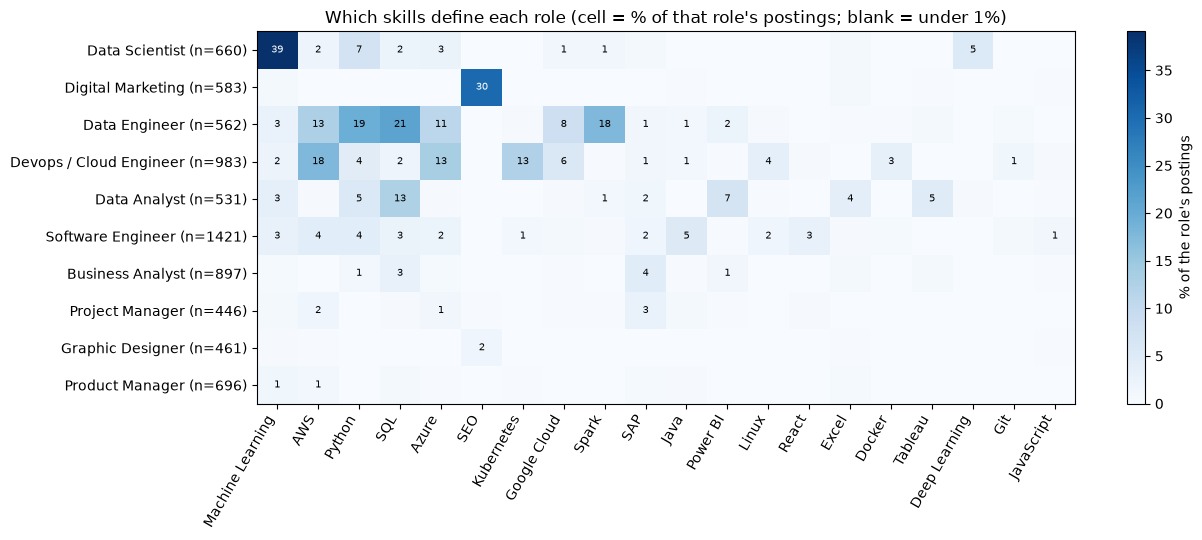

,top 3 skills (% of the role's postings)
Data Scientist,"Machine Learning (39%), Python (7%), Deep Lear..."
Digital Marketing,"SEO (30%), Machine Learning (1%), Excel (1%)"
Data Engineer,"SQL (21%), Python (19%), Spark (18%)"
Devops / Cloud Engineer,"AWS (18%), Azure (13%), Kubernetes (13%)"
Data Analyst,"SQL (13%), Power BI (7%), Python (5%)"
Software Engineer,"Java (5%), AWS (4%), Python (4%)"
Business Analyst,"SAP (4%), SQL (3%), Power BI (1%)"
Project Manager,"SAP (3%), AWS (2%), Azure (1%)"
Graphic Designer,"SEO (2%), Machine Learning (0%), AWS (0%)"
Product Manager,"Machine Learning (1%), AWS (1%), SQL (1%)"


In [7]:
# By role: share of that role's postings that mention each skill (denominator = role's own postings).
by_role_n = M.groupby(df["role"]).sum()
role_sizes = df["role"].value_counts()
by_role_pct = (100 * by_role_n.div(role_sizes, axis=0))[order]

long = (by_role_n.stack().rename("frequency").reset_index()
        .rename(columns={"level_1": "skill"}))
long["role_postings"] = long["role"].map(role_sizes)
long["pct_of_role_postings"] = (100 * long["frequency"] / long["role_postings"]).round(2)
long.to_csv(FIG / "skill_demand_by_role.csv", index=False)

role_order = by_role_pct.max(axis=1).sort_values(ascending=False).index
data = by_role_pct.loc[role_order]
fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(data.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=60, ha="right")
ax.set_yticks(range(len(role_order)), [f"{r} (n={role_sizes[r]})" for r in role_order])
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        if v >= 1:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > data.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, label="% of the role's postings")
ax.set_title("Which skills define each role (cell = % of that role's postings; blank = under 1%)")
plt.tight_layout()
fig.savefig(FIG / "02_role_skill_heatmap.png", dpi=120)
plt.show()

top3 = {r: ", ".join(f"{s} ({by_role_pct.loc[r, s]:.0f}%)" for s in by_role_pct.loc[r].nlargest(3).index) for r in role_order}
display(pd.Series(top3, name="top 3 skills (% of the role's postings)").to_frame())

## 4. Skill co-occurrence

Two skills **co-occur** when the same posting mentions both. For a pair (A, B): `together` = postings
with both; `lift` = together ÷ (what we would expect if A and B were unrelated) — above 1 means they
appear together more than chance; `jaccard` = together ÷ postings with A or B. Only pairs seen in at
least 5 postings are ranked, because lift from 1–2 postings is noise.

122 of 190 possible pairs occur at least once; 75 occur in >= 5 postings


,skill_a,skill_b,together,lift,jaccard
0,Python,SQL,133,11.22,0.294
1,AWS,Azure,87,7.40,0.173
2,AWS,Python,76,5.55,0.137
3,Python,Spark,75,14.79,0.217
4,SQL,Spark,69,13.89,0.200
5,AWS,Kubernetes,55,8.20,0.129
6,SQL,Azure,55,5.41,0.112
7,Python,Azure,55,5.30,0.111
8,AWS,Google Cloud,54,8.91,0.131
9,Python,Machine Learning,50,3.21,0.080


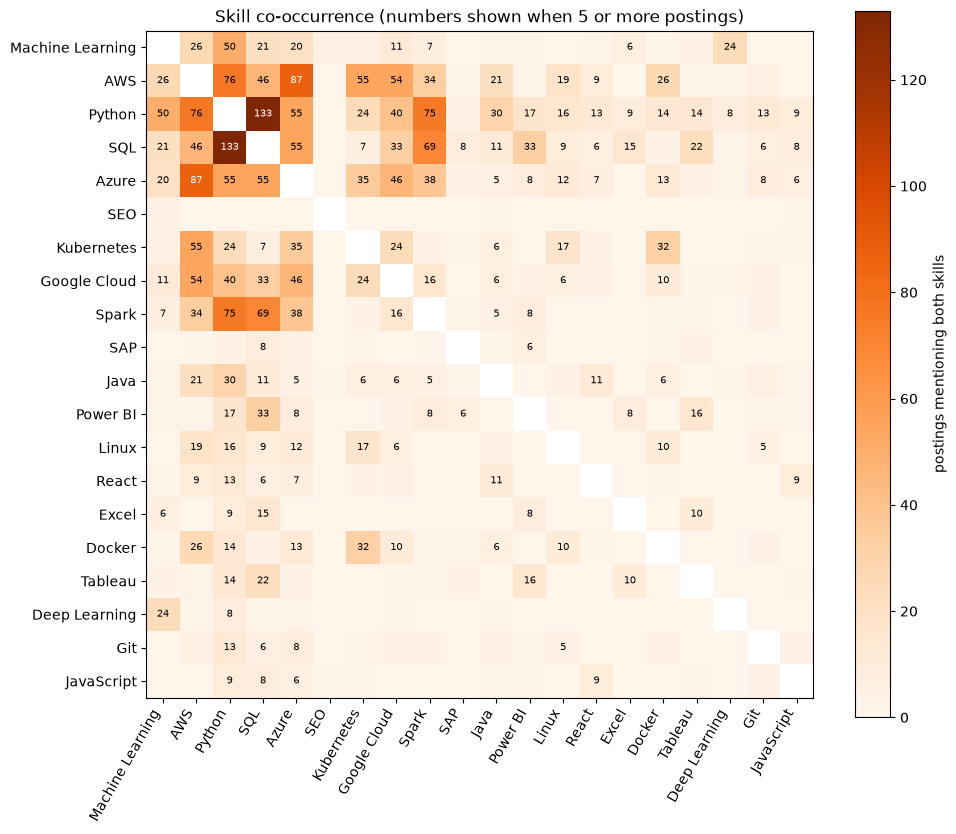

In [8]:
Mi = M.astype(int)
C = Mi.T @ Mi                       # co-occurrence counts, diagonal = skill frequency
f = M.sum()
pairs = []
for i, a in enumerate(skills):
    for b in skills[i + 1:]:
        together = int(C.loc[a, b])
        if together == 0:
            continue
        expected = f[a] * f[b] / N
        pairs.append({"skill_a": a, "skill_b": b, "together": together,
                      "lift": round(together / expected, 2),
                      "jaccard": round(together / (f[a] + f[b] - together), 3)})
pairs = pd.DataFrame(pairs).sort_values(["together", "lift"], ascending=False).reset_index(drop=True)
pairs.to_csv(FIG / "cooccurrence_pairs.csv", index=False)
print(f"{len(pairs)} of {len(skills) * (len(skills) - 1) // 2} possible pairs occur at least once; "
      f"{int((pairs['together'] >= 5).sum())} occur in >= 5 postings")
display(pairs[pairs["together"] >= 5].head(15))

cm = C.loc[order, order].values.astype(float)
np.fill_diagonal(cm, np.nan)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm, cmap="Oranges")
ax.set_xticks(range(len(order)), order, rotation=60, ha="right")
ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        v = cm[i, j]
        if not np.isnan(v) and v >= 5:
            ax.text(j, i, f"{int(v)}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanmax(cm) * 0.6 else "black")
fig.colorbar(im, ax=ax, label="postings mentioning both skills")
ax.set_title("Skill co-occurrence (numbers shown when 5 or more postings)")
plt.tight_layout()
fig.savefig(FIG / "03_cooccurrence_heatmap.png", dpi=120)
plt.show()

## 5. Topic modelling (LDA) — meaning beyond bag-of-words

The skill dictionary only finds skills we already know to look for. **Latent Dirichlet Allocation** finds
word groups ("topics") that go together across postings without being told any skills. We fit it on the
**distinct** descriptions only (so a description posted 20 times does not dominate a topic) on counts with
very common words (in over 50% of postings) and very rare words (under 5 postings) removed.

**How the number of topics is chosen (rule fixed before running):** hold out 20% of the postings
(`random_state=42`), fit candidates K = 4, 6, 8, 10 on the other 80%, and choose the K with the **lowest
held-out perplexity**. We also report how well the dominant topic lines up with the posting's role
(normalised mutual information) as a sanity check, not as the selection criterion.

In [9]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import normalized_mutual_info_score

pool = df.loc[uniq].reset_index(drop=True)
cv_l = CountVectorizer(min_df=5, max_df=0.5)
XL = cv_l.fit_transform(pool["description_clean"].fillna(""))
lda_terms = np.array(cv_l.get_feature_names_out())
perm = np.random.RandomState(RS).permutation(XL.shape[0])
cut = int(0.8 * len(perm))
tr, te = perm[:cut], perm[cut:]
print(f"LDA input: {XL.shape[0]:,} distinct postings x {XL.shape[1]:,} terms  (train {len(tr):,} / held-out {len(te):,})")

sweep = []
for k in (4, 6, 8, 10):
    m = LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=25, random_state=RS).fit(XL[tr])
    dom = m.transform(XL).argmax(axis=1)
    sweep.append({"K": k, "held_out_perplexity": round(float(m.perplexity(XL[te])), 1),
                  "NMI_vs_role": round(normalized_mutual_info_score(pool["role"], dom), 3)})
sweep = pd.DataFrame(sweep)
K_FINAL = int(sweep.loc[sweep["held_out_perplexity"].idxmin(), "K"])
sweep.to_csv(FIG / "lda_k_selection.csv", index=False)
display(sweep)
print("K chosen by the pre-set rule (lowest held-out perplexity):", K_FINAL)

LDA input: 6,362 distinct postings x 3,549 terms  (train 5,089 / held-out 1,273)


,K,held_out_perplexity,NMI_vs_role
0,4,1022.7,0.271
1,6,1078.7,0.345
2,8,1139.6,0.288
3,10,1175.5,0.294


K chosen by the pre-set rule (lowest held-out perplexity): 4


,,top 10 words
topic,name,
0,Employer & company description,"company, technology, global, team, work, custo..."
1,"Marketing, design & project delivery","marketing, digital, project, role, design, exp..."
2,"Data, analytics & business/product","datum, business, data, role, product, team, ex..."
3,"Engineering, cloud & software","engineer, cloud, software, role, platform, app..."


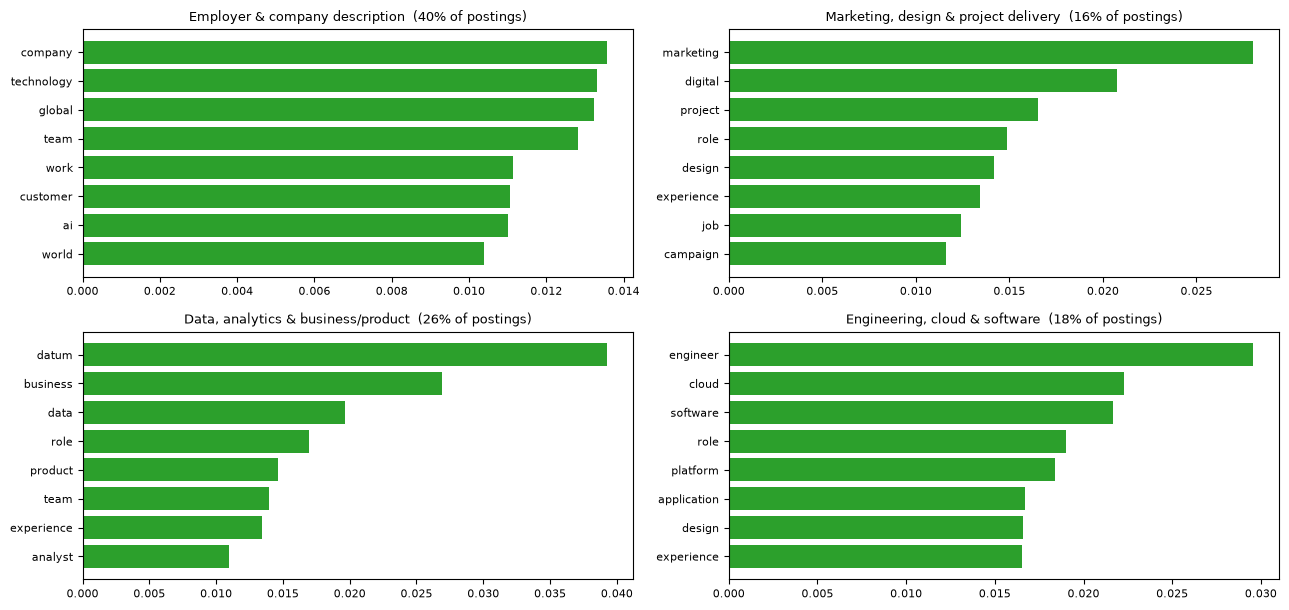

,0: Employer & company description,"1: Marketing, design & project delivery","2: Data, analytics & business/product","3: Engineering, cloud & software"
role,,,,
Business Analyst,40.1,1.4,56.4,2.0
Data Analyst,36.0,3.8,59.1,1.1
Data Engineer,32.2,1.2,52.3,14.2
Data Scientist,51.7,1.4,45.6,1.4
Devops / Cloud Engineer,35.8,0.6,3.5,60.1
Digital Marketing,18.5,81.1,0.2,0.2
Graphic Designer,19.7,79.8,0.0,0.4
Product Manager,55.6,6.5,34.1,3.9
Project Manager,32.7,38.3,25.3,3.6


In [10]:
lda = LatentDirichletAllocation(n_components=K_FINAL, learning_method="batch", max_iter=25,
                                random_state=RS).fit(XL)
comp = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

TOPIC_NAMES = {0: "Employer & company description", 1: "Marketing, design & project delivery",
               2: "Data, analytics & business/product", 3: "Engineering, cloud & software"}
# Names were assigned by reading the top words above (they are our interpretation, not model output).
tname = lambda t: TOPIC_NAMES.get(t, f"Topic {t}")

tw = []
for t in range(K_FINAL):
    for rank, j in enumerate(np.argsort(comp[t])[::-1][:10], 1):
        tw.append({"topic": t, "name": tname(t), "rank": rank, "term": lda_terms[j], "weight": round(float(comp[t, j]), 4)})
tw = pd.DataFrame(tw)
tw.to_csv(FIG / "lda_topic_words.csv", index=False)
display(tw.groupby(["topic", "name"])["term"].apply(lambda s: ", ".join(s)).to_frame("top 10 words"))

# Share of each role's postings assigned to each topic (all 7,240 postings, same fitted model).
XA = cv_l.transform(df["description_clean"].fillna(""))
dom_all = lda.transform(XA).argmax(axis=1)
topic_role = pd.crosstab(df["role"], pd.Series(dom_all, name="topic"), normalize="index").mul(100).round(1)
topic_role.columns = [f"{c}: {tname(c)}" for c in topic_role.columns]
topic_role.to_csv(FIG / "lda_topic_by_role.csv")

ncols = 2 if K_FINAL <= 8 else 5
nrows = int(np.ceil(K_FINAL / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 2.6 * nrows + 1), squeeze=False)
for t, ax in enumerate(axes.ravel()[:K_FINAL]):
    idx = np.argsort(comp[t])[::-1][:8][::-1]
    ax.barh(lda_terms[idx], comp[t][idx], color="tab:green")
    ax.set_title(f"{tname(t)}  ({100 * (dom_all == t).mean():.0f}% of postings)", fontsize=9)
    ax.tick_params(labelsize=8)
for ax in axes.ravel()[K_FINAL:]:
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG / "04_lda_topics.png", dpi=120)
plt.show()
display(topic_role)

## 6. Which postings does each topic describe? (role check)

If the topics are meaningful, a role should concentrate in a few topics. The table above shows, for each
role, the share of its postings assigned to each topic.

## 7. Joining the two halves of Method 1: skills inside each text cluster

`text_mining_research.ipynb` clustered the postings from their text alone (7 clusters). Here we ask: do
the clusters differ in which skills they mention? We join on `job_id`.

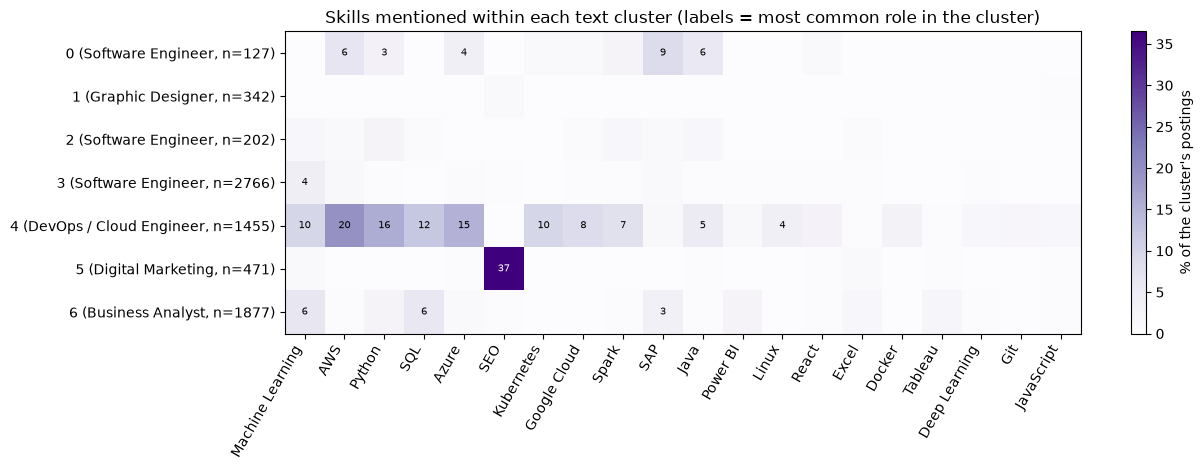

,any_skill
cluster,
"0 (Software Engineer, n=127)",29.9
"1 (Graphic Designer, n=342)",1.2
"2 (Software Engineer, n=202)",6.4
"3 (Software Engineer, n=2766)",8.1
"4 (DevOps / Cloud Engineer, n=1455)",59.5
"5 (Digital Marketing, n=471)",37.8
"6 (Business Analyst, n=1877)",18.9


In [11]:
cl = pd.read_csv(ROOT / "outputs" / "text_mining_research" / "final_cluster_assignments.csv")[["job_id", "cluster"]]
csum = pd.read_csv(ROOT / "outputs" / "text_mining_research" / "final_cluster_summary.csv")
label = {int(r.cluster): f"{int(r.cluster)} ({r.top_roles.split(' (')[0]}, n={int(r['size'])})" for _, r in csum.iterrows()}

J = df[["job_id"]].join(M).merge(cl, on="job_id", how="left")
assert J["cluster"].notna().all(), "every posting must have a cluster"
cl_pct = (100 * J.groupby("cluster")[skills].mean())[order]
cl_pct["any_skill"] = 100 * J.groupby("cluster")[skills].apply(lambda g: (g.sum(axis=1) > 0).mean())
cl_pct.round(1).to_csv(FIG / "skill_share_by_cluster.csv")

fig, ax = plt.subplots(figsize=(13, 4.8))
view = cl_pct[order]
im = ax.imshow(view.values, cmap="Purples", aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=60, ha="right")
ax.set_yticks(range(len(view)), [label[int(c)] for c in view.index])
for i in range(view.shape[0]):
    for j in range(view.shape[1]):
        v = view.values[i, j]
        if v >= 3:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > view.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, label="% of the cluster's postings")
ax.set_title("Skills mentioned within each text cluster (labels = most common role in the cluster)")
plt.tight_layout()
fig.savefig(FIG / "05_cluster_skill_heatmap.png", dpi=120)
plt.show()
display(cl_pct.round(1)[["any_skill"]].assign(cluster=[label[int(c)] for c in cl_pct.index]).set_index("cluster"))

## 8. Validating the skill extraction

Counting words is only useful if the counts are right. This section answers "how do you know the numbers
are correct?" with four pieces of evidence, each from reading real postings:

1. **Ambiguity audit** — every distinct context in which *Spark*, *Excel* and *React* (the three words that
   are also ordinary English or share a name with something else) matched, each judged by reading it.
2. **Precision sample** — 60 matches (3 per skill) judged by reading.
3. **Recall sample** — 100 random postings, read in full, listing every one of the 20 skills they mention
   *without looking at the regex output*. V2 was designed after seeing this sample, so it is **in-sample**.
4. **Holdout recall sample** — a **second** 100 random postings, none overlapping the first, labelled
   *after V2 was frozen*. This is the honest test.

**Who labelled.** Every label in these files was written by the AI assistant (GitHub Copilot) reading the
text, and each file records this in a `labelled_by` column. They are **not** human-verified. A teammate
should re-label a random subset (for example 25 postings and 15 matches) and report the agreement before
presenting these numbers as final.

**Labelling rules (fixed before labelling):** a skill counts as present when the visible text names it or an
alias of the same technology (`amazon web services`, `gcp`/`google cloud platform`, `k8s`, `ml` when it
means machine learning, `pyspark` and `apache spark`, `reactjs`/`react native`, `powerbi`, `search engine
optimisation`, `microsoft azure`/`azure devops`, `ms excel` as the spreadsheet). Related but different tools
(GitHub, GitLab, TypeScript, Node.js, neural networks, BigQuery) do **not** count. Only the first 500
characters exist, so a skill beyond them cannot be labelled.

In [12]:
from math import sqrt

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

# ---- 1. Ambiguity audit: every distinct context of the three ambiguous words, judged by reading.
aud = pd.read_csv(FIG / "ambiguous_skill_audit.csv")
rows = []
for s in ["Spark", "Excel", "React"]:
    d = aud[aud["skill"] == s]
    keep = d["context"].apply(lambda c: bool(re.search(PATTERNS[s], c)))
    n1, f1 = int(d["n_matches"].sum()), int(d.loc[d["is_correct"] == 0, "n_matches"].sum())
    n2, f2 = int(d.loc[keep, "n_matches"].sum()), int(d.loc[keep & (d["is_correct"] == 0), "n_matches"].sum())
    rows.append({"skill": s, "V1_matches": n1, "V1_false": f1, "V1_precision": round(1 - f1 / n1, 3),
                 "V2_matches": n2, "V2_false": f2, "V2_precision": round(1 - f2 / n2, 3),
                 "true_matches_lost_by_V2": int(d.loc[~keep & (d["is_correct"] == 1), "n_matches"].sum())})
audit_tbl = pd.DataFrame(rows).set_index("skill")
audit_tbl.to_csv(FIG / "ambiguity_audit_summary.csv")
display(audit_tbl)
print("What V1 got wrong (judged by reading):")
for _, r in aud[aud["is_correct"] == 0].iterrows():
    print(f"  {r['skill']:5s} x{int(r['n_matches']):2d} ...{r['context']}...")
print("\nWhat V2 still gets wrong:")
for _, r in aud[(aud["is_correct"] == 0) & aud["context"].apply(lambda c: bool(re.search(PATTERNS['Excel'], c)))
                & (aud["skill"] == "Excel")].iterrows():
    print(f"  {r['skill']:5s} x{int(r['n_matches']):2d} ...{r['context']}...")

,V1_matches,V1_false,V1_precision,V2_matches,V2_false,V2_precision,true_matches_lost_by_V2
skill,,,,,,,
Spark,76,19,0.750,57,0,1.000,0
Excel,58,17,0.707,47,6,0.872,0
React,44,0,1.000,44,0,1.000,0


What V1 got wrong (judged by reading):
  Spark x 1 ...they used for almost everything online. this spark became lok…...
  Spark x13 ...they used for almost everything online. this spark became lokal. our first instinct was to put ...
  Spark x 1 ...egnyte your career. spark your passion. egnyte is a place where we spa...
  Spark x 1 ...description egnyte your career. spark your passion. egnyte is a place where we spa...
  Spark x 1 ...they used for almost everything online. this spark be…...
  Spark x 1 ...udiences. our work is designed to be shared, spark conversations, and contribute to contemporar...
  Spark x 1 ...ource, and campaign we create is designed to spark curiosity and joy. if you're a designer with...
  Excel x 7 ...ings, learn new skills and discover what you excel at—all from day one. job description respons...
  Excel x 2 ...ided with all the necessary opportunities to excel in life. people are at the core of everythin...
  Excel x 5 ...ironment that encourages you to 

In [13]:
# ---- 2. Precision sample (60 matches drawn from V1 matches, 3 per skill, judged by reading).
prec = pd.read_csv(FIG / "extraction_precision_sample.csv")
assert prec["is_correct"].notna().all(), "precision sample not fully labelled"
src = df.set_index("job_id")["description_raw"].fillna("").str.lower()
still = prec.apply(lambda r: bool(re.search(PATTERNS[r["skill"]], src[r["job_id"]])), axis=1)
k, n = int(prec["is_correct"].sum()), len(prec)
lo, hi = wilson(k, n)
print(f"V1 precision on the 60-match sample: {k}/{n} = {k / n:.3f}  (95% CI {lo:.3f}-{hi:.3f})")
print(f"matches V2 would still report: {int(still.sum())}/{n}; the one V1 error "
      f"({prec.loc[prec['is_correct'] == 0, 'skill'].tolist()}) is removed by V2: "
      f"{bool((~still & (prec['is_correct'] == 0)).any())}")
print("NOTE: the sample is only 3 matches per skill, so it cannot see rare ambiguity; the audit above can.")

V1 precision on the 60-match sample: 59/60 = 0.983  (95% CI 0.911-0.997)
matches V2 would still report: 59/60; the one V1 error (['Excel']) is removed by V2: True
NOTE: the sample is only 3 matches per skill, so it cannot see rare ambiguity; the audit above can.


In [14]:
# ---- 3 + 4. Recall and false-match checks on two labelled samples of 100 postings each.
def load_truth(path):
    s = pd.read_csv(path)
    assert s["skills_present"].notna().all(), f"{path.name} not fully labelled"
    truth = s["skills_present"].astype(str).apply(
        lambda t: set() if t.strip().upper() == "NONE" else {x.strip() for x in t.split(";") if x.strip()})
    unknown = set().union(*truth) - set(skills)
    assert not unknown, f"labels not in the skill list: {unknown}"
    return s, truth

def score(P, s, truth):
    pred = s["description_raw"].fillna("").str.lower().apply(lambda t: {k for k in skills if re.search(P[k], t)})
    tp = sum(len(a & b) for a, b in zip(truth, pred))
    fn = sum(len(a - b) for a, b in zip(truth, pred))
    fp = sum(len(b - a) for a, b in zip(truth, pred))
    missed = [f"#{i}: {', '.join(sorted(a - b))}" for i, (a, b) in enumerate(zip(truth, pred)) if a - b]
    return tp, fn, fp, missed

res = []
for name, path, note in (("sample 1 (V2 designed after seeing it: in-sample)", FIG / "extraction_recall_sample.csv", "in-sample"),
                         ("holdout (V2 frozen before labelling: out-of-sample)", FIG / "extraction_holdout_sample.csv", "holdout")):
    s, truth = load_truth(path)
    for ver, P in (("V1", PATTERNS_V1), ("V2", PATTERNS)):
        tp, fn, fp, missed = score(P, s, truth)
        lo, hi = wilson(tp, tp + fn)
        res.append({"sample": name, "version": ver, "true_mentions": tp + fn, "found": tp, "missed": fn,
                    "false_matches": fp, "recall": round(tp / (tp + fn), 3), "recall_95CI": f"{lo:.2f}-{hi:.2f}",
                    "precision": round(tp / (tp + fp), 3) if tp + fp else float("nan"),
                    "postings_with_a_skill": int((truth.apply(len) > 0).sum()), "missed_detail": "; ".join(missed)})
val = pd.DataFrame(res)
val.to_csv(FIG / "extraction_validation_summary.csv", index=False)
display(val.drop(columns="missed_detail"))
for _, r in val[val["missed"] > 0].iterrows():
    print(f"{r['version']} missed in {r['sample'].split(' (')[0]}: {r['missed_detail']}")

,sample,version,true_mentions,found,missed,false_matches,recall,recall_95CI,precision,postings_with_a_skill
0,sample 1 (V2 designed after seeing it: in-sample),V1,41,37,4,0,0.902,0.77-0.96,1.0,29
1,sample 1 (V2 designed after seeing it: in-sample),V2,41,41,0,0,1.000,0.91-1.00,1.0,29
2,holdout (V2 frozen before labelling: out-of-sa...,V1,44,41,3,0,0.932,0.82-0.98,1.0,22
3,holdout (V2 frozen before labelling: out-of-sa...,V2,44,44,0,0,1.000,0.92-1.00,1.0,22


V1 missed in sample 1: #9: Spark; #35: Machine Learning; #48: Spark; #80: Spark
V1 missed in holdout: #35: Machine Learning; #36: React; #80: Spark


## 9. Write the contract file `data/review2/skill_demand.csv`

Exactly the 20 skills in the frozen config, ranked 1–20 by posting frequency (ties alphabetical).
Members C and D read this file; the schema `skill, frequency, pct_postings, rank` must not change.

In [15]:
out = demand[["skill", "frequency", "pct_postings", "rank"]]
assert len(out) == 20 and set(out["skill"]) == set(skills)
assert out["rank"].tolist() == list(range(1, 21))
assert out["frequency"].is_monotonic_decreasing
out_path = ROOT / "data" / "review2" / "skill_demand.csv"
out.to_csv(out_path, index=False)
print(f"wrote {len(out)} skills -> {out_path.relative_to(ROOT)}")
out

wrote 20 skills -> data\review2\skill_demand.csv


,skill,frequency,pct_postings,rank
0,Machine Learning,381,5.26,1
1,AWS,335,4.63,2
2,Python,296,4.09,3
3,SQL,290,4.01,4
4,Azure,254,3.51,5
5,SEO,188,2.60,6
6,Kubernetes,145,2.00,7
7,Google Cloud,131,1.81,8
8,Spark,124,1.71,9
9,SAP,114,1.57,10


## 10. Interpretation & limitations

**What the evidence supports**
- **Demand ranking (§3).** Across 7,240 postings the most-mentioned listed skills are Machine Learning
  (381 postings, 5.26%), AWS (335), Python (296), SQL (290) and Azure (254), then SEO, Kubernetes, Google
  Cloud, Spark and SAP. The ranking is robust: recounting on the 6,362 distinct descriptions only gives a
  Spearman correlation of 1.000 and the same order. Read the *ranking*; the percentages are lower bounds
  (see below).
- **Machine Learning is #1 only because of how it is counted.** Under the original dictionary (V1) it was
  #4 (282 postings) because only the full phrase "machine learning" matched. Counting the abbreviation
  "ML" adds 99 postings; we read 30 random "ML" contexts and all were machine learning ("ai/ml", "ml
  models", "ml ops"). Spark rose from 76 to 124 for a similar reason (67 postings mention only "PySpark").
  Say this if asked why the ranking differs from an earlier version.
- **Roles are defined by different skills (§3, figure 02).** Machine Learning appears in 39% of Data
  Scientist postings (258); SEO in 30% of Digital Marketing; SQL (21%), Python (19%) and Spark (18%) lead
  Data Engineer; AWS (18%), Azure (13%) and Kubernetes (13%) lead DevOps/Cloud; SQL (13%), Power BI (7%)
  and Tableau (5%) lead Data Analyst.
- **Skills come in bundles (§4, figure 03).** 122 of the 190 possible skill pairs occur at least once and
  75 occur in five or more postings. The biggest: Python + SQL (133 postings, lift 11.2), AWS + Azure (87,
  lift 7.4), Python + Spark (75, lift 14.8), SQL + Spark (69, lift 13.9). The strongest links are tool
  families: Kubernetes + Docker (32 postings, lift 38.0), Power BI + Tableau (lift 41.8), Machine Learning +
  Deep Learning (24, lift 12.3). SEO appears with another listed skill in at most 4 postings: marketing and
  engineering postings ask for separate skill worlds.
- **Topics (§5).** LDA with K = 4, chosen by the rule fixed in advance (lowest held-out perplexity,
  1022.7), finds: employer/company description, marketing-design-project delivery, data-analytics-business,
  and engineering-cloud-software. It separates Digital Marketing (81% in the marketing topic), Graphic
  Designer (80%) and DevOps/Cloud (60% in the engineering topic) well; it separates Software Engineer
  poorly (50% land in the employer-description topic) because that topic captures boilerplate shared by
  many postings. K = 6 lines up better with role (NMI 0.345 vs 0.271) but has worse perplexity; we report
  the rule-based choice and show both.
- **The two halves agree (§7).** Postings clustered by text alone (Member A's notebook) differ strongly in
  how many listed skills they mention: 59.5% of the DevOps/Cloud cluster, 37.8% of the marketing cluster,
  1.2% of the graphic-design cluster. Skills were not used to build the clusters, so this is independent
  support. It does not make the clustering strong: its own silhouette is 0.083.

**How we know the extraction is right (§8) — and how far that goes**
- **Ambiguity audit.** We read every distinct context of the three words that double as ordinary English.
  Original dictionary: Spark 75% correct (19 of 76 matches were "this spark became…", "spark your passion",
  "spark conversations"), Excel 71% (17 of 58 were the verb: "excel at", "excel in life"), React 100%. After
  the fixes: Spark 100% (0 of 57 original matches wrong), Excel 87% (6 of 47 wrong), with **no true match
  lost**. The 6 remaining Excel errors are "innovate and excel" (5) and "gpus excel" (1), left unpatched on
  purpose rather than hard-coding one-off phrases.
- **Precision sample.** 59 of 60 sampled matches were correct (98.3%, 95% CI 91–99.7%). The one error is
  the Excel verb, now fixed. Because the sample has only 3 matches per skill it cannot see rare ambiguity;
  the audit above is the stronger evidence.
- **Recall, two samples of 100 postings.** On sample 1 the original dictionary found 37 of 41 skill
  mentions (recall 0.902); on a **second, unseen** sample it found 41 of 44 (0.932). The misses were
  PySpark-only postings, the "ML" abbreviation and "ReactJS". The improved dictionary, **frozen before the
  second sample was read**, found 44 of 44 with no false matches (recall 1.00, 95% CI 0.92–1.00).
- **Limits of this validation.** (1) **Every label was written by the AI assistant, not by a human** (see
  the `labelled_by` column); a teammate should re-label a subset and report agreement before these figures
  are called final. (2) The improvements for Spark and Excel were designed from the same audit that
  measures them, so those two precision figures are in-sample. (3) Only 22 of the 100 holdout postings
  mention a listed skill, so the confidence interval is wide, and the holdout contained no "excel"
  verb or "spark" noun, so it does not test those fixes. (4) Labels cover only the visible 500 characters.

**What it does not support — say these before being asked**
1. **Counts are lower bounds.** 98.5% of descriptions are exactly at the 500-character cap. **76.8% of
   postings (5,562) mention none of the 20 listed skills**, 23.2% mention at least one, 8.6% at least two,
   3.7% at least three. A skill's true requirement rate is higher than shown; a missing skill may simply be
   beyond character 500.
2. **Co-occurrence rests on few postings.** Only 621 postings mention two or more skills, so lift values
   for rare pairs are noisy. We only rank pairs seen in at least 5 postings.
3. **Roles with few matches are not "skill-free".** Business Analyst, Project Manager, Product Manager and
   Graphic Designer score at most 4% on any listed skill because the dictionary covers technical skills.
   Their requirements (stakeholder management, roadmaps, design tools) are not in it.
4. **A dictionary only finds skills we already listed.** The TF-IDF terms (§2) and LDA topics (§5) are the
   parts that find structure without being told the skills.
5. **Scope.** Postings cover about three months and India only; a posting counts once per skill; repeated
   postings of the same description are kept in the main count (they are separate openings) and shown not
   to change the ranking. Topic names are our reading of the top words, not model output. The word "datum"
   in the topics comes from the Review-1 lemmatiser turning "data" into "datum"; we did not change it.